# Tema 16 · De la neurona a la red: perceptrón y MLP

Neuronas artificiales, activaciones y por qué hacen falta capas.

Este cuaderno es el tema 16 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/16-de-la-neurona-a-la-red-perceptron-y-mlp/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

En muchas casas, la luz de la escalera tiene dos interruptores: uno abajo y otro arriba. Puedes prenderla desde abajo y apagarla al llegar arriba. Si anotas la posición de cada interruptor (0 o 1) y si la luz está prendida, sale una tabla de cuatro filas: la luz se prende **cuando los dos interruptores están en posiciones distintas**. A esa regla se le llama **XOR** («o exclusivo»).

| Interruptor de abajo | Interruptor de arriba | ¿Luz prendida? |
|---|---|---|
| 0 | 0 | no (0) |
| 0 | 1 | sí (1) |
| 1 | 0 | sí (1) |
| 1 | 1 | no (0) |

Parece el problema de clasificación más fácil del mundo: dos entradas, cuatro ejemplos, ningún ruido. Y sin embargo, la regresión logística del tema 8 **no puede** aprenderlo, por más que la entrenes. Este tema explica por qué, y cómo lo resuelve una idea muy simple: poner varias neuronas juntas, en capas. Esa idea es la base de todas las redes neuronales.

En este tema vas a:

- calcular a mano la salida de una **neurona artificial**;
- entrenar un **perceptrón** con su regla y ver por qué no resuelve XOR;
- comparar las activaciones **sigmoide**, **tanh** y **ReLU** (forma, rango y derivada);
- escribir en NumPy el paso hacia adelante de una **red de varias capas** (un MLP) y predecir el `shape` de cada matriz;
- explicar por qué apilar capas sin activación no sirve de nada.

Necesitas lo del tema 8 (la sigmoide, la frontera de decisión y la entropía cruzada) y lo del tema 6 (pesos, término independiente y descenso de gradiente). Cómo se entrena una red de varias capas es el tema 17; aquí los pesos los vas a elegir tú.

## Actividad: arma una neurona

Una neurona hace dos cosas: calcula un puntaje con dos pesos y un término independiente, como la logística, y lo pasa por una **activación**. En la actividad, cada celda del plano se pinta según lo que responde la neurona en ese lugar: coral si dice «1», tinta si dice «0», y más intenso cuanto más segura está. Las cuatro esquinas son los cuatro casos de la tabla de los interruptores (o de otra regla que elijas).

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/16-de-la-neurona-a-la-red-perceptron-y-mlp/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Con la regla **Y** (la luz se prende solo si los dos interruptores están en 1), mueve el término independiente *b* hasta colorear bien las cuatro esquinas. ¿Qué hace *b* con la recta?
2. Cambia a la regla **O** y vuelve a acertar las cuatro. ¿Qué cambiaste?
3. Cambia a la regla **XOR**. Intenta todo lo que quieras con *w*₁, *w*₂, *b* y las cuatro activaciones. ¿Cuántas esquinas logras acertar como máximo?
4. Pasa al modo **Red para XOR**. Ahora hay dos neuronas ocultas, cada una con su recta, y una neurona de salida que combina lo que dicen. Busca pesos que coloreen bien las cuatro esquinas. Si te rindes, pulsa «Mostrar una solución» y mira qué recta traza cada neurona oculta.

La idea de todo el tema está en ese último paso: **cada neurona oculta traza una recta y la salida combina sus respuestas**. Con una recta no se puede separar XOR; con dos, sí.

## Una neurona

Una **neurona artificial** recibe varias entradas *x*₁, *x*₂, …, multiplica cada una por su **peso**, suma un **término independiente** *b* (en inglés, *bias*; en la actividad, «término *b*») y pasa el resultado por una función llamada **activación** *f*:

$$z = {w}_{1} {x}_{1} + {w}_{2} {x}_{2} + \cdots + b \qquad a = f ( z )$$

*z* es la **suma ponderada** (el puntaje del tema 8) y *a* es la **salida** de la neurona. Si la activación es la sigmoide, una neurona es exactamente una regresión logística: misma fórmula, mismo dibujo, otro nombre. El nombre viene de una analogía vieja y bastante libre con las neuronas del cerebro, que reciben señales de otras y «se disparan» si la suma pasa de un umbral; no te la tomes al pie de la letra.

La activación más antigua es el **escalón**: da 1 si *z* es mayor o igual que 0, y 0 si no. Calculemos a mano una neurona con dos entradas, *x* = (2, −1), pesos *w* = (0,5; 1,5) y término independiente *b* = 0,25:

$$z = 0,5 \cdot 2 + 1,5 \cdot ( - 1 ) + 0,25 = 1 - 1,5 + 0,25 = - 0,25$$

Como *z* es negativo, el escalón da 0. La sigmoide da un número un poco menor que 0,5. En Python, la suma ponderada es un producto punto (tema 3):

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def escalon(z):
    """1 si z >= 0, y 0 si no."""
    return np.where(z >= 0, 1, 0)

def sigmoide(z):
    """La del tema 8: aplasta cualquier número a un valor entre 0 y 1."""
    return 1 / (1 + np.exp(-z))

def neurona(x, w, b, activacion):
    """Suma ponderada más b, pasada por una activación."""
    z = np.dot(w, x) + b
    return activacion(z)

x = np.array([2.0, -1.0])     # dos entradas
w = np.array([0.5, 1.5])      # un peso por entrada
b = 0.25                      # el término independiente

print("z =", np.dot(w, x) + b)
print("Con escalón: ", neurona(x, w, b, escalon))
print("Con sigmoide:", neurona(x, w, b, sigmoide).round(3))

z = -0.25
Con escalón:  0
Con sigmoide: 0.438


Igual que en el tema 8, los puntos donde *z* = 0 forman una **recta** en el plano (*x*₁, *x*₂). De un lado de la recta la neurona dice 1 y del otro, 0. Los pesos inclinan la recta y el término independiente la corre sin girarla: es lo que viste en la actividad.

## El perceptrón

El **perceptrón** (Frank Rosenblatt, 1958) es una neurona con activación escalón y una regla para aprender sus pesos. La regla es casi de sentido común. Se recorren los ejemplos uno por uno:

- si la neurona **acierta**, no se cambia nada;
- si dice 0 y era 1, se **suma** a los pesos un poquito de la entrada, para que *z* suba la próxima vez;
- si dice 1 y era 0, se **resta**, para que *z* baje.

Las tres cosas caben en una fórmula, con *ŷ* la predicción, *y* la clase real y *η* (eta) la tasa de aprendizaje:

$$\mathbf{w} \leftarrow \mathbf{w} + \eta \cdot ( y - \hat{y} ) \cdot \mathbf{x} \qquad b \leftarrow b + \eta \cdot ( y - \hat{y} )$$

Si acierta, *y* − *ŷ* vale 0 y nada cambia; si no, vale +1 o −1. Una pasada completa por todos los ejemplos se llama **época**. Probémoslo con dos grupos de puntos sintéticos que una recta puede separar:

In [ ]:
rng = np.random.default_rng(42)

# 50 puntos alrededor de cada centro (datos sintéticos)
X_sep = np.vstack([rng.normal([-1, -1], 0.6, size=(50, 2)),
                   rng.normal([1.2, 1.0], 0.6, size=(50, 2))])
y_sep = np.array([0] * 50 + [1] * 50)
orden = rng.permutation(100)          # mezclamos las dos clases
X_sep, y_sep = X_sep[orden], y_sep[orden]

def entrenar_perceptron(X, y, epocas=15, tasa=0.1):
    """La regla del perceptrón. Devuelve w, b y los errores por época."""
    w = np.zeros(X.shape[1])
    b = 0.0
    errores = []
    for epoca in range(epocas):
        fallos = 0
        for xi, yi in zip(X, y):
            pred = escalon(np.dot(w, xi) + b)
            # Si acierta, yi - pred vale 0 y nada cambia
            w = w + tasa * (yi - pred) * xi
            b = b + tasa * (yi - pred)
            fallos += int(pred != yi)
        errores.append(fallos)
    return w, b, errores

w_sep, b_sep, errores_sep = entrenar_perceptron(X_sep, y_sep)
print("Errores en cada época:", errores_sep)
print("w =", w_sep.round(3), "  b =", round(b_sep, 3))

Errores en cada época: [2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
w = [0.175 0.141]   b = 0.0


Desde la segunda época ya no se equivoca con ningún punto, y desde ahí la regla no cambia nada más. Rosenblatt demostró que esto no es suerte: si existe una recta que separa las dos clases, el perceptrón la encuentra en un número finito de pasos. A unos datos así se les dice **linealmente separables**.

### XOR: el problema que una recta no resuelve

Ahora hagamos lo mismo con XOR. Para tener más que cuatro puntos, ponemos 100 puntos sintéticos alrededor de las cuatro esquinas, cada uno con la clase de su esquina:

In [ ]:
esquinas = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
clase_xor = np.array([0, 1, 1, 0])    # 1 si los interruptores difieren

cual = rng.integers(0, 4, size=100)   # a qué esquina va cada punto
X_xor = esquinas[cual] + rng.normal(0, 0.15, size=(100, 2))
y_xor = clase_xor[cual]

w_x, b_x, errores_xor = entrenar_perceptron(X_xor, y_xor)
print("Errores en cada época:", errores_xor)

Errores en cada época: [47, 52, 57, 48, 50, 47, 52, 57, 51, 48, 52, 57, 48, 45, 53]


Los errores nunca llegan a cero: cada vez que la regla arregla un punto, desarregla otros, y la recta da vueltas sin rumbo. Con 100 puntos, equivocarse en unos 50 es lo mismo que adivinar con una moneda. Miremos las dos situaciones. Las regiones se pintan como en el tema 8: clasificamos cada punto de una cuadrícula fina.

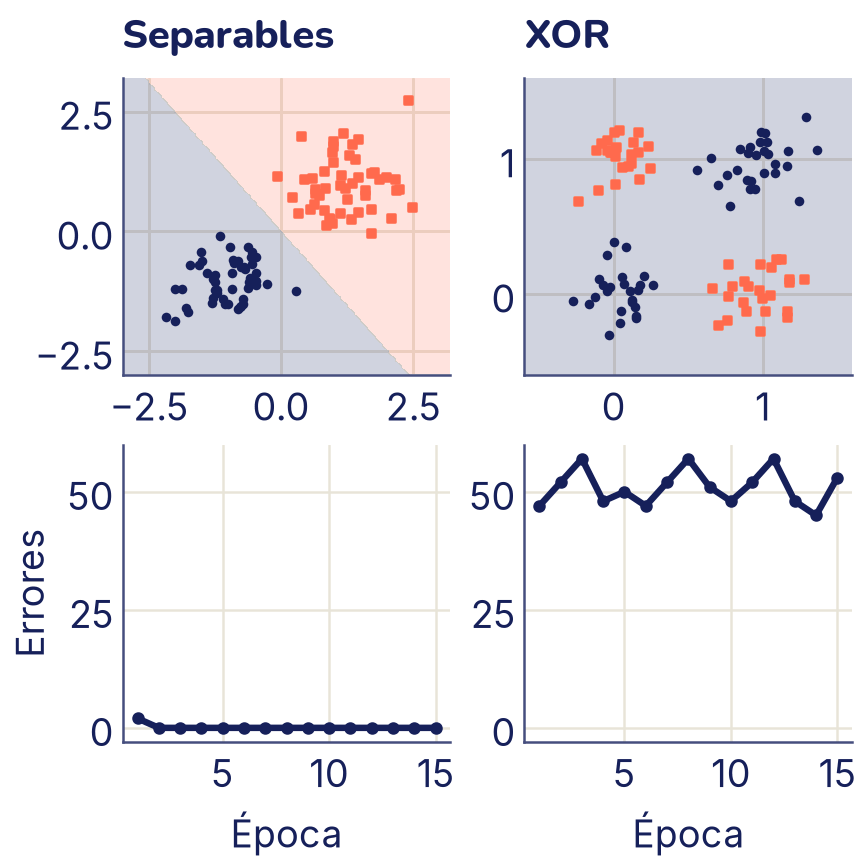

In [ ]:
def dibujar_clases(X, y, ax=None, s=30):
    """Clase 0: círculos de color C0. Clase 1: cuadrados de color C1."""
    ax = ax or plt.gca()
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=s, color="C0",
               marker="o", label="Clase 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=s, color="C1",
               marker="s", label="Clase 1")

def regiones(ax, predecir, x_lim, y_lim):
    """Pinta de C0 o C1, muy claro, la clase que predice cada lugar."""
    A, B = np.meshgrid(np.linspace(*x_lim, 200), np.linspace(*y_lim, 200))
    zona = predecir(np.column_stack([A.ravel(), B.ravel()]))
    ax.contourf(A, B, zona.reshape(A.shape), levels=[-0.5, 0.5, 1.5],
                colors=["C0", "C1"], alpha=0.2)

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
casos = [(X_sep, y_sep, w_sep, b_sep, errores_sep, (-3, 3.2),
          "Separables"),
         (X_xor, y_xor, w_x, b_x, errores_xor, (-0.6, 1.6), "XOR")]
for col, (X_c, y_c, w_c, b_c, err, lim, nombre) in enumerate(casos):
    arriba, abajo = ejes[0, col], ejes[1, col]
    regiones(arriba, lambda P: escalon(P @ w_c + b_c), lim, lim)
    dibujar_clases(X_c, y_c, ax=arriba, s=8)
    arriba.set_title(nombre)
    abajo.plot(range(1, 16), err, color="C0", marker="o", markersize=4)
    abajo.set_ylim(-3, 60)
    abajo.set_xlabel("Época")
ejes[1, 0].set_ylabel("Errores")
plt.show()

¿Por qué ninguna recta sirve para XOR? En la figura de arriba a la derecha, la última recta que probó el perceptrón ni siquiera cruza los datos: todo el recuadro quedó del lado de la clase 0. Pero no es culpa de la regla. Los círculos están en dos esquinas **opuestas**, (0, 0) y (1, 1), y los cuadrados en las otras dos. Cualquier recta que deje los dos círculos de un lado deja también, de ese lado, al menos un cuadrado. También se puede ver con números. Para que una neurona escalón acierte XOR haría falta:

- en (0, 0), decir 0: *b* menor que 0;
- en (0, 1) y en (1, 0), decir 1: *w*₂ + *b* ≥ 0 y *w*₁ + *b* ≥ 0;
- en (1, 1), decir 0: *w*₁ + *w*₂ + *b* menor que 0.

Sumando las dos del medio, *w*₁ + *w*₂ + 2*b* ≥ 0. Pero la primera y la última dicen que *b* y *w*₁ + *w*₂ + *b* son negativos, y su suma, que es la misma *w*₁ + *w*₂ + 2*b*, también tendría que ser negativa. Es una contradicción: **ningún** perceptrón resuelve XOR. Lo mismo vale para la logística y para cualquier modelo cuya frontera sea una recta. En 1969, Marvin Minsky y Seymour Papert publicaron este tipo de límites en un libro que enfrió por años el entusiasmo por las neuronas artificiales. La salida, como viste en la actividad, es usar **más de una neurona**.

## Funciones de activación

Antes de armar redes, conozcamos las activaciones que se usan hoy. El escalón tiene un problema serio: su derivada es 0 en todas partes (salvo en el salto, donde no existe). Como el descenso de gradiente del tema 6 necesita derivadas que digan hacia dónde mover los pesos, con el escalón no hay pista. Por eso las redes usan activaciones suaves:

- **Sigmoide**, σ(*z*), la del tema 8: va de 0 a 1.
- **Tangente hiperbólica**, tanh(*z*) = (*e*ᶻ − *e*⁻ᶻ)/(*e*ᶻ + *e*⁻ᶻ): la misma forma de S, pero de −1 a 1 y centrada en 0. De hecho, es una sigmoide estirada: tanh(*z*) = 2σ(2*z*) − 1.
- **ReLU** (*rectified linear unit*): ReLU(*z*) = máx(0, *z*). Deja pasar los positivos tal cual y cambia los negativos por 0. Es la más usada en redes modernas.

Sus derivadas, que en el tema 17 serán protagonistas, salen así (la de la ReLU es más simple todavía: vale 1 si *z* es positivo y 0 si es negativo):

$${\sigma}^{'} ( z ) = \sigma ( z ) \cdot ( 1 - \sigma ( z ) ) \qquad {\mathrm{tanh}}^{'} ( z ) = 1 - {\mathrm{tanh}}^{2} ( z )$$

In [ ]:
def tanh(z):
    return np.tanh(z)

def relu(z):
    """Los positivos pasan igual; los negativos se vuelven 0."""
    return np.maximum(0, z)

def d_sigmoide(z):
    return sigmoide(z) * (1 - sigmoide(z))

def d_tanh(z):
    return 1 - np.tanh(z) ** 2

def d_relu(z):
    # En z = 0 la derivada no existe; por convención se usa 0
    return np.where(z > 0, 1.0, 0.0)

activaciones = [("sigmoide", sigmoide, d_sigmoide),
                ("tanh", tanh, d_tanh),
                ("ReLU", relu, d_relu)]
for nombre, f, df in activaciones:
    print(f"{nombre:8s} f(-5) = {f(-5.0):5.2f}  f(0) = {f(0.0):.2f}"
          f"  f(5) = {f(5.0):.2f}  f'(0) = {df(0.0):.2f}"
          f"  f'(5) = {df(5.0):.4f}")

sigmoide f(-5) =  0.01  f(0) = 0.50  f(5) = 0.99  f'(0) = 0.25  f'(5) = 0.0066
tanh     f(-5) = -1.00  f(0) = 0.00  f(5) = 1.00  f'(0) = 1.00  f'(5) = 0.0002
ReLU     f(-5) =  0.00  f(0) = 0.00  f(5) = 5.00  f'(0) = 0.00  f'(5) = 1.0000


0.25 ** 10 = 9.5e-07


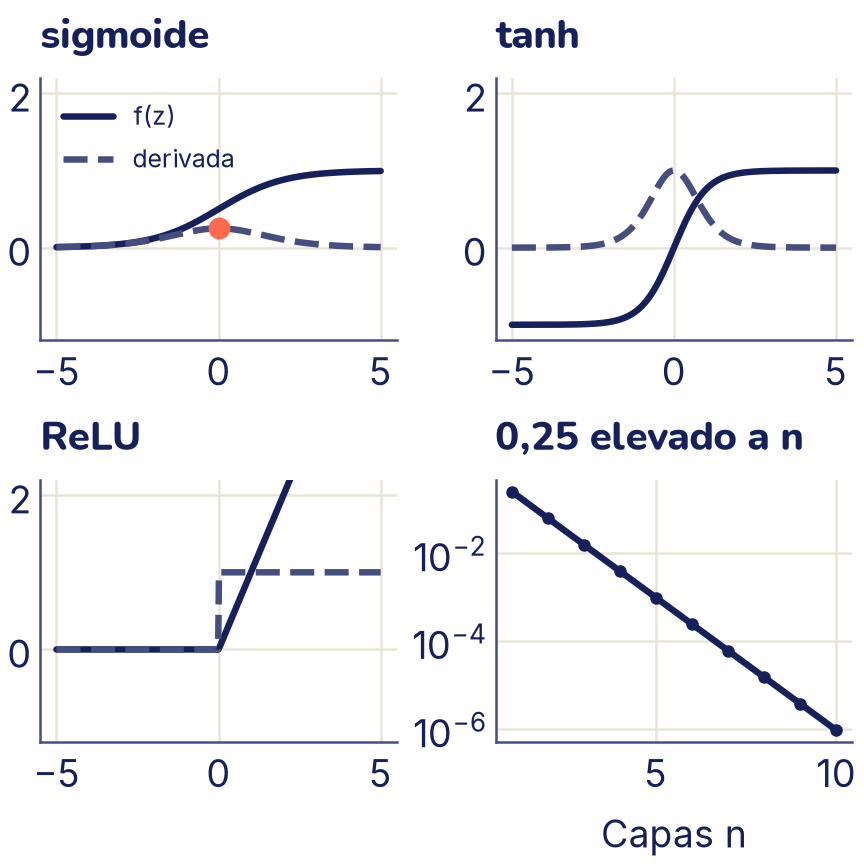

In [ ]:
zs = np.linspace(-5, 5, 400)
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for eje, (nombre, f, df) in zip(ejes.flat, activaciones):
    eje.plot(zs, f(zs), color="C0", label="f(z)")
    eje.plot(zs, df(zs), color="C2", linestyle="--", label="derivada")
    eje.set_title(nombre)
    eje.set_ylim(-1.2, 2.2)
ejes[0, 0].scatter([0], [0.25], color="C1", s=60, zorder=3)
ejes[0, 0].legend(loc="upper left", fontsize=10)

# La derivada de la sigmoide vale como mucho 0,25: tras n capas,
# el gradiente puede quedar multiplicado por 0,25 ** n
capas = np.arange(1, 11)
ejes[1, 1].semilogy(capas, 0.25 ** capas, color="C0", marker="o",
                    markersize=4)
ejes[1, 1].set_title("0,25 elevado a n")
ejes[1, 1].set_xlabel("Capas n")
plt.show()

print(f"0.25 ** 10 = {0.25 ** 10:.1e}")

Comparemos:

| | Sigmoide | tanh | ReLU |
|---|---|---|---|
| Rango | de 0 a 1 | de −1 a 1 | de 0 a infinito |
| Derivada máxima | 0,25 | 1 | 1 (en todos los positivos) |
| Derivada lejos del 0 | casi 0 en los dos lados | casi 0 en los dos lados | 1 a la derecha, 0 a la izquierda |
| Uso típico hoy | la salida de una clasificación binaria | algunas redes que procesan secuencias | las capas ocultas de casi todas las redes |

La sigmoide y la tanh se **saturan**: lejos del 0 son casi planas y su derivada casi se anula. Eso trae un problema que entenderás bien en el tema 17. Allí vas a ver que, para ajustar los pesos de las primeras capas, la red multiplica las derivadas de todas las capas que hay en el camino. Con la sigmoide, cada derivada vale como mucho 0,25, así que con diez capas el producto puede ser menor que una millonésima: las primeras capas casi no reciben señal y aprenden muy lento. Es el **desvanecimiento del gradiente**. La ReLU tiene derivada 1 en todos los positivos y lo sufre mucho menos; por eso, y porque es muy barata de calcular, es la opción por defecto en las capas ocultas.

## De la neurona a la red

Una **capa** es un grupo de neuronas que reciben las mismas entradas, cada una con sus propios pesos. Un **perceptrón multicapa** (**MLP**, por *multilayer perceptron*) pone capas una detrás de otra: las salidas de una capa son las entradas de la siguiente. Las capas del medio se llaman **ocultas** porque no vemos sus valores en los datos; solo vemos la entrada y la salida. El número de neuronas de una capa es su **ancho** y el número de capas es la **profundidad**. Una red «2-2-1» tiene 2 entradas, una capa oculta de 2 neuronas y 1 neurona de salida. (A pesar del nombre, las neuronas de un MLP casi nunca usan el escalón del perceptrón.)

### XOR con pesos elegidos a mano

Construyamos una red 2-2-1 que resuelva XOR. La idea es pensar XOR como «**O**, pero **no Y**»: la luz se prende si al menos un interruptor está en 1, salvo que estén los dos.

- La neurona oculta 1 calcula **O**: con pesos 6 y 6 y término independiente −3, su puntaje es positivo en cuanto una entrada vale 1.
- La neurona oculta 2 calcula **Y**: con los mismos pesos y término independiente −9, solo es positivo si las dos valen 1.
- La neurona de salida calcula «*h*₁ y no *h*₂»: peso 8 para *h*₁, peso −8 para *h*₂ y término independiente −4.

Todas usan la sigmoide; los pesos grandes la vuelven casi un escalón, pero suave. Con matrices, una capa entera se calcula de una vez. Si ponemos los cuatro ejemplos como filas de *X*, de forma (4, 2), y los pesos de cada neurona como una **columna** de *W*₁, de forma (2, 2):

$$H = \sigma ( X {W}_{1} + {\mathbf{b}}_{1} ) \qquad \hat{\mathbf{y}} = \sigma ( H {W}_{2} + {b}_{2} )$$

*H* tiene una fila por ejemplo y una columna por neurona oculta. El término independiente se suma a cada fila por *broadcasting* (tema 3).

In [ ]:
X4 = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y4 = np.array([0, 1, 1, 0])           # XOR

# Cada columna de W1 son los pesos de una neurona oculta
W1 = np.array([[6.0, 6.0],
               [6.0, 6.0]])
b1 = np.array([-3.0, -9.0])           # neurona 1: «O»; neurona 2: «Y»
W2 = np.array([[8.0],
               [-8.0]])               # «h1 y no h2»
b2 = np.array([-4.0])

H = sigmoide(X4 @ W1 + b1)            # (4, 2) @ (2, 2) -> (4, 2)
salida = sigmoide(H @ W2 + b2)        # (4, 2) @ (2, 1) -> (4, 1)

print("x1 x2 |   h1    h2  | salida | XOR")
for xi, hi, si, yi in zip(X4, H, salida[:, 0], y4):
    print(f" {xi[0]}  {xi[1]} | {hi[0]:.3f} {hi[1]:.3f} |"
          f"  {si:.3f} |  {yi}")

x1 x2 |   h1    h2  | salida | XOR
 0  0 | 0.047 0.000 |  0.026 |  0
 0  1 | 0.953 0.047 |  0.962 |  1
 1  0 | 0.953 0.047 |  0.962 |  1
 1  1 | 1.000 0.953 |  0.026 |  0


Las cuatro salidas están del lado correcto de 0,5, y bien lejos. Lo interesante es la columna del medio: la capa oculta **transformó** los datos. En el espacio (*h*₁, *h*₂), las esquinas (0, 1) y (1, 0) caen en el mismo lugar, cerca de (0,95; 0,05), y los otros dos casos quedan en (0, 0) y (1; 0,95). Ahí, una sola recta los separa sin problema: la de la neurona de salida. Veamos lo que hace cada neurona en todo el plano. Pintamos su salida en **bandas** de un solo color por lado: coral donde pasa de 0,5 y tinta donde no, más intenso cuanto más lejos de 0,5.

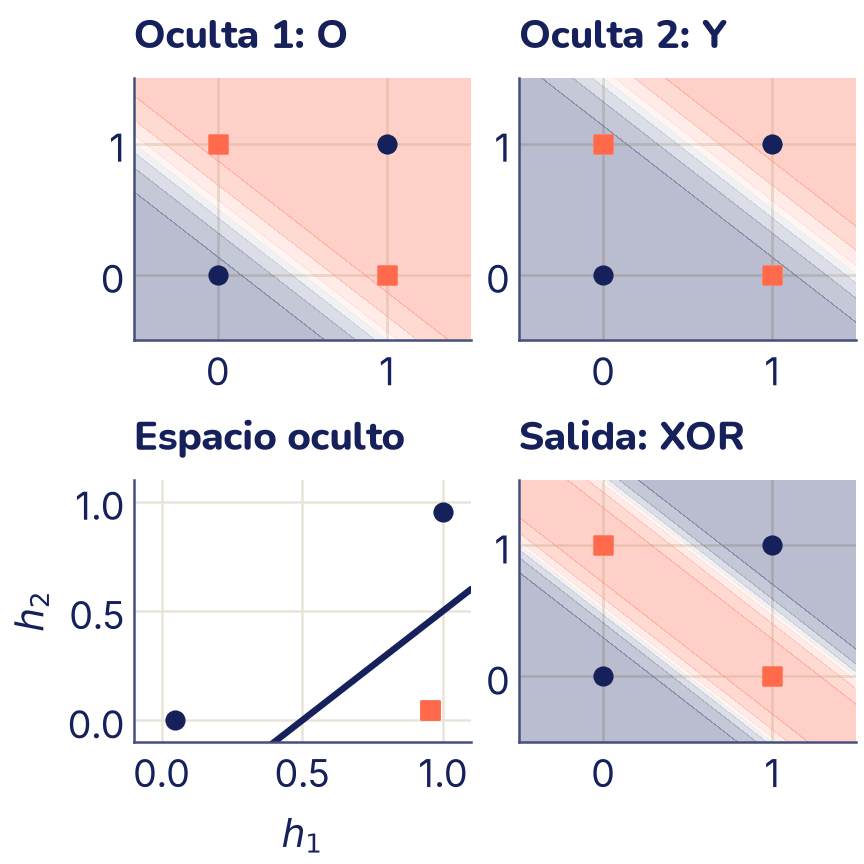

In [ ]:
def pintar_salida(ax, A, B, P):
    """Bandas coral si P >= 0.5 y tinta si no, más fuertes lejos de 0.5."""
    cortes = [0, 0.1, 0.25, 0.4, 0.5, 0.6, 0.75, 0.9, 1]
    for bajo, alto in zip(cortes[:-1], cortes[1:]):
        color = "C1" if bajo >= 0.5 else "C0"
        lejos = max(abs(bajo - 0.5), abs(alto - 0.5))
        ax.contourf(A, B, P, levels=[bajo, alto], colors=color,
                    alpha=0.6 * lejos)

A, B = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
plano = np.column_stack([A.ravel(), B.ravel()])
H_plano = sigmoide(plano @ W1 + b1)
sal_plano = sigmoide(H_plano @ W2 + b2)

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
paneles = [(ejes[0, 0], H_plano[:, 0], "Oculta 1: O"),
           (ejes[0, 1], H_plano[:, 1], "Oculta 2: Y"),
           (ejes[1, 1], sal_plano[:, 0], "Salida: XOR")]
for eje, valores, titulo in paneles:
    pintar_salida(eje, A, B, valores.reshape(A.shape))
    dibujar_clases(X4, y4, ax=eje, s=50)
    eje.set_title(titulo)

# Lo que ve la neurona de salida: los cuatro casos en el espacio (h1, h2)
dibujar_clases(H, y4, ax=ejes[1, 0], s=50)
h = np.linspace(-0.1, 1.1, 2)
# Frontera de la salida: 8·h1 - 8·h2 - 4 = 0, o sea h2 = h1 - 0.5
ejes[1, 0].plot(h, h - 0.5, color="C0")
ejes[1, 0].set_xlim(-0.1, 1.1)
ejes[1, 0].set_ylim(-0.1, 1.1)
ejes[1, 0].set_title("Espacio oculto")
ejes[1, 0].set_xlabel("$h_1$")
ejes[1, 0].set_ylabel("$h_2$")
plt.show()

La salida de la red ya no es una recta: es una **franja** entre dos rectas paralelas, una de cada neurona oculta. Así se construyen fronteras curvas o con forma: cada neurona oculta aporta un corte recto y la capa siguiente los combina. Con más neuronas, más cortes, y la frontera puede tomar casi cualquier forma.

### El paso hacia adelante, para cualquier red

Calcular la salida de una red a partir de la entrada se llama **paso hacia adelante** (en inglés, *forward pass*). Para cualquier número de capas es el mismo bucle: multiplicar por la matriz de pesos, sumar el término independiente, aplicar la activación y pasar el resultado a la capa siguiente. La última capa no lleva la activación de las ocultas; qué lleva depende de la tarea, como verás más abajo.

Lo más útil para no perderse es seguir el `shape` de cada matriz. Con *n* ejemplos y una capa que pasa de *a* entradas a *m* neuronas, la cuenta es (*n*, *a*) @ (*a*, *m*), que da (*n*, *m*): el número del medio tiene que coincidir y «desaparece», y el término independiente tiene un número por neurona, de forma (*m*,).

In [ ]:
def adelante(X, capas, activacion=relu, ver=False):
    """Paso hacia adelante de un MLP. capas: una lista de pares (W, b)."""
    A = X
    for i, (W, b) in enumerate(capas):
        Z = A @ W + b
        if ver:
            print(f"Capa {i + 1}: {A.shape} @ {W.shape} + {b.shape}"
                  f" -> {Z.shape}")
        ultima = i == len(capas) - 1
        # Las capas ocultas llevan activación; la última sale tal cual
        A = Z if ultima else activacion(Z)
    return A

rng = np.random.default_rng(0)
# Una red 2-4-1 con pesos al azar: de 2 entradas a 4 ocultas, y a 1
red = [(rng.normal(size=(2, 4)), np.zeros(4)),
       (rng.normal(size=(4, 1)), np.zeros(1))]
X5 = rng.normal(size=(5, 2))          # cinco ejemplos
salida5 = adelante(X5, red, ver=True)

# La misma función, con la red de XOR y sigmoide en la salida
z_xor = adelante(X4, [(W1, b1), (W2, b2)], activacion=sigmoide)
print("XOR:", sigmoide(z_xor).ravel().round(3))

Capa 1: (5, 2) @ (2, 4) + (4,) -> (5, 4)
Capa 2: (5, 4) @ (4, 1) + (1,) -> (5, 1)
XOR: [0.026 0.962 0.962 0.026]


Una red así es una **composición de funciones**: cada capa es una función que recibe lo que devolvió la anterior. Una red con dos capas ocultas calcula *f*₃(*f*₂(*f*₁(*x*))), donde cada *f* es «multiplicar, sumar y activar». Las redes enormes de los últimos temas de la ruta son, en el fondo, muchas capas así compuestas.

### Contar parámetros

Cada capa que pasa de *a* entradas a *m* neuronas tiene una matriz de *a* × *m* pesos y *m* términos independientes. Los parámetros de la red son la suma de todas las capas:

In [ ]:
def contar_parametros(tamanos):
    """Pesos y términos independientes de un MLP con capas de esos tamaños."""
    total = 0
    for a, m in zip(tamanos[:-1], tamanos[1:]):
        # matriz (a, m) y un término independiente por neurona
        total += a * m + m
    return total

for tamanos in [[2, 2, 1], [2, 4, 1], [784, 128, 10]]:
    print(tamanos, "->", contar_parametros(tamanos), "parámetros")

[2, 2, 1] -> 9 parámetros
[2, 4, 1] -> 17 parámetros
[784, 128, 10] -> 101770 parámetros


La red de XOR tiene 9 parámetros: los 9 deslizadores del modo «Red para XOR» de la actividad. La última es una red típica para imágenes de 28 × 28 píxeles (784 entradas) y 10 clases, como las que vas a entrenar en el tema 18: con una sola capa oculta ya pasa de cien mil parámetros. Casi todos están en la primera capa, porque cada píxel se conecta con cada neurona oculta.

### ¿Y si no hay activación?

Podría parecer que la activación es un detalle. No lo es: sin ella, apilar capas **no sirve de nada**. Si dos capas solo multiplican y suman, se pueden juntar en una:

$$( X {V}_{1} + {\mathbf{c}}_{1} ) {V}_{2} + {\mathbf{c}}_{2} = X \underbrace{( {V}_{1} {V}_{2} )}_{V} + \underbrace{( {\mathbf{c}}_{1} {V}_{2} + {\mathbf{c}}_{2} )}_{\mathbf{c}}$$

Comprobémoslo con números:

In [ ]:
rng = np.random.default_rng(1)
V1, c1 = rng.normal(size=(2, 4)), rng.normal(size=4)
V2, c2 = rng.normal(size=(4, 1)), rng.normal(size=1)

dos_capas = (X5 @ V1 + c1) @ V2 + c2  # dos capas, sin activación
V, c = V1 @ V2, c1 @ V2 + c2          # una sola capa equivalente
una_capa = X5 @ V + c

print("Forma de V:", V.shape)
print("¿Dan lo mismo?", np.allclose(dos_capas, una_capa))

Forma de V: (2, 1)
¿Dan lo mismo? True


Diez capas lineales seguidas siguen siendo **una** capa lineal, con una frontera recta, y XOR sigue sin resolverse. La activación es lo que «dobla» el espacio entre una capa y la siguiente, como hizo la sigmoide con las esquinas de XOR. Por eso se llama a las activaciones **no lineales**, y por eso son indispensables.

### La salida y la pérdida según la tarea

Las capas ocultas son parecidas en casi todas las redes. Lo que cambia según el problema es la **última capa** y la **pérdida** con que se entrena. Son las mismas que ya conoces:

| Tarea | Última capa | Activación de salida | Pérdida |
|---|---|---|---|
| Regresión: predecir un número | 1 neurona | ninguna | MSE (tema 6) |
| Clasificación binaria | 1 neurona | sigmoide | entropía cruzada binaria (tema 8) |
| Clasificación en *K* clases | *K* neuronas | softmax | entropía cruzada categórica (tema 8) |

Una regresión lineal es una red sin capas ocultas y sin activación de salida; una regresión logística es una red sin capas ocultas con sigmoide a la salida. Las redes neuronales no reemplazan lo que aprendiste en la fase 2: lo extienden con capas ocultas.

## Un adelanto: una red que aprende sola

Elegir pesos a mano funciona con 9 parámetros, no con cien mil. Las redes aprenden sus pesos con descenso de gradiente, como la recta del tema 6 y la logística del tema 8. La parte difícil es calcular el gradiente de la pérdida respecto de **cada** peso de **cada** capa; el método para hacerlo, la **retropropagación** (*backpropagation*), es el tema 17. Mientras tanto, scikit-learn trae un MLP listo, `MLPClassifier`, con la misma interfaz `fit` y `predict` de siempre.

Volvamos a las dos lunas del tema 8, con la misma división en entrenamiento y validación. Allí, la logística, con su frontera recta, acertaba el 85 % en validación. Probemos un MLP con una capa oculta de 1, 3, 10 y 100 neuronas. Usamos `solver="lbfgs"`, un método de optimización más refinado que el descenso de gradiente básico, que funciona bien con pocos datos; la activación de las capas ocultas es la ReLU, que es la opción por defecto.

Ancho   1:  aciertos al entrenar 0.83   en validación 0.85
Ancho   3:  aciertos al entrenar 0.84   en validación 0.82
Ancho  10:  aciertos al entrenar 0.91   en validación 0.97
Ancho 100:  aciertos al entrenar 1.00   en validación 0.85


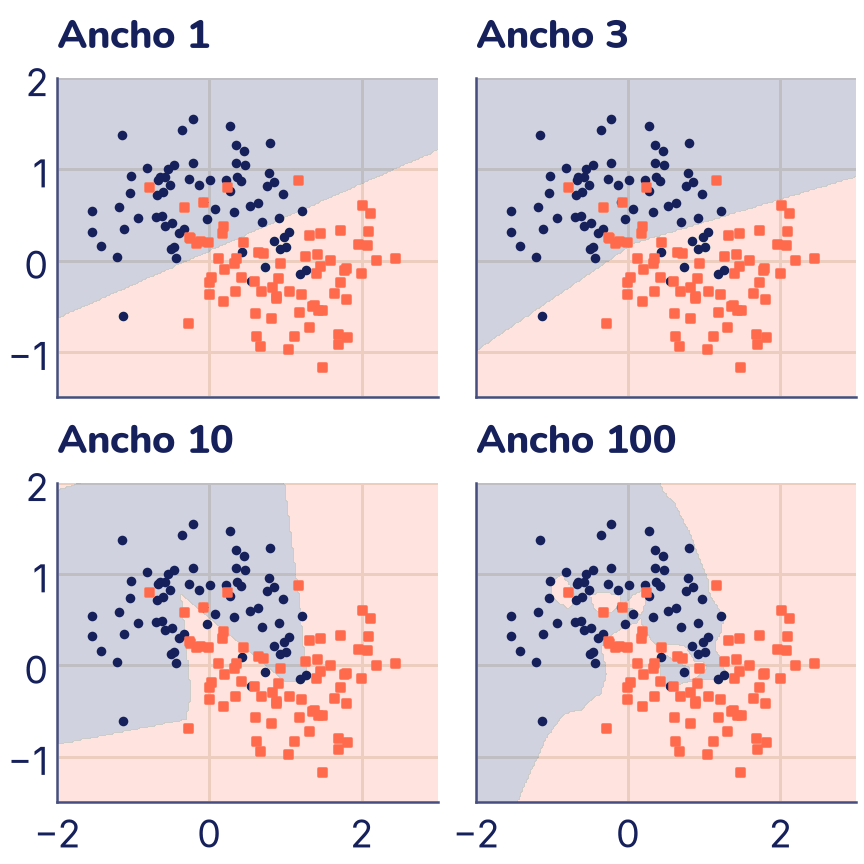

In [ ]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

# Las mismas lunas y la misma división del tema 8
X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X_entr, X_val, y_entr, y_val = train_test_split(
    X, y, test_size=0.3, random_state=0)

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8),
                         sharex=True, sharey=True)
for eje, ocultas in zip(ejes.flat, [1, 3, 10, 100]):
    red_mlp = MLPClassifier(hidden_layer_sizes=(ocultas,),
                            solver="lbfgs", max_iter=2000,
                            random_state=0)
    red_mlp.fit(X_entr, y_entr)
    regiones(eje, red_mlp.predict, (-2, 3), (-1.5, 2))
    dibujar_clases(X_entr, y_entr, ax=eje, s=8)
    eje.set_title(f"Ancho {ocultas}")
    print(f"Ancho {ocultas:3d}:  aciertos al entrenar "
          f"{red_mlp.score(X_entr, y_entr):.2f}"
          f"   en validación {red_mlp.score(X_val, y_val):.2f}")
plt.show()

Es la misma historia de los temas 7 y 8, ahora con el ancho de la red:

- Con **1 neurona oculta**, la frontera es una recta y le va igual que a la logística (85 % en validación). Tiene sentido: con una sola ReLU, la salida solo puede crecer en una dirección, así que la frontera sigue siendo el corte de una sola recta.
- Con **3**, la red puede quebrar un poco la frontera, pero con estos pesos apenas la dobla y no mejora.
- Con **10**, la frontera se curva siguiendo las lunas y acierta el 97 % en validación.
- Con **100**, acierta todos los puntos de entrenamiento pero solo el 85 % en validación: la frontera se retuerce para rodear puntos sueltos que son ruido. La red **memorizó**, igual que k-NN con *k* = 1.

Más neuronas dan más rectas para combinar y fronteras más flexibles, pero también más capacidad para sobreajustar. El ancho y la profundidad son hiperparámetros, y se eligen como siempre: mirando la validación. Lo vas a practicar en el mini-proyecto.

## Lo que aprendiste y lo que sigue

- Una **neurona** calcula una suma ponderada más un término independiente, *z* = *w*·*x* + *b*, y la pasa por una **activación**. Con la sigmoide, una neurona es una regresión logística.
- El **perceptrón** usa el escalón y la regla *w* ← *w* + *η*(*y* − *ŷ*)*x*. Encuentra una recta que separa las clases cuando existe, pero ninguna recta resuelve **XOR**.
- La **sigmoide** (de 0 a 1) y la **tanh** (de −1 a 1) se saturan y su derivada se anula lejos del 0; la de la sigmoide vale como mucho 0,25, lo que provoca el **desvanecimiento del gradiente** en redes profundas. La **ReLU** es la opción por defecto en las capas ocultas.
- Un **MLP** apila capas; cada una calcula *f*(*AW* + *b*). Siguiendo los `shape`s, (*n*, *a*) @ (*a*, *m*) da (*n*, *m*). Una capa de *a* a *m* tiene *a*·*m* + *m* parámetros.
- Sin activación, varias capas equivalen a una sola. Con ella, cada neurona oculta traza una recta y las siguientes las combinan en fronteras con forma.
- La última capa y la pérdida dependen de la tarea: sin activación y MSE para regresión, sigmoide y entropía cruzada para dos clases, softmax y entropía cruzada para varias.

En el tema 17 vas a abrir la caja de `fit`: programar desde cero cómo una red calcula el gradiente de cada peso con la regla de la cadena, y entrenar con él un MLP pequeño en estas mismas lunas.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las funciones y variables de la teoría: `escalon`, `sigmoide`, `tanh`, `relu`, `d_sigmoide`, `neurona`, `entrenar_perceptron`, `adelante`, `contar_parametros`, `X4` (las cuatro esquinas) y las dos lunas (`X_entr`, `X_val`, `y_entr`, `y_val`). En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Haz primero a mano, con lápiz, lo que se pide a mano: la computadora es para comprobar.

## Ejercicios

### 1. Una neurona a mano

Una neurona tiene pesos *w* = (2, −1) y término independiente *b* = 0,5. Llega la entrada *x* = (1, 3).

1. Calcula la suma ponderada *z*.
2. Calcula la salida con el escalón y con la ReLU. Sin calculadora, di si la sigmoide da más o menos que 0,5 y si la tanh da un número positivo o negativo.
3. ¿Cuánto tendría que valer el término independiente para que el escalón diga 1? Da el valor más chico posible.

<details>
<summary>Respuesta</summary>

1. *z* = 2 · 1 + (−1) · 3 + 0,5 = 2 − 3 + 0,5 = **−0,5**.
2. Como *z* es negativo, el escalón da **0** y la ReLU también da **0**. La sigmoide de un número negativo es **menor que 0,5**, y la tanh de un número negativo es **negativa**.
3. El escalón dice 1 cuando *z* ≥ 0. Sin *b*, la suma vale 2 − 3 = −1, así que hace falta *b* ≥ 1: el valor más chico es **b = 1**, que deja *z* justo en 0.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
x = np.array([1.0, 3.0])
w = np.array([2.0, -1.0])
for nombre, f in [("escalón", escalon), ("sigmoide", sigmoide),
                  ("tanh", tanh), ("ReLU", relu)]:
    print(f"{nombre:8s} b = 0.5: {neurona(x, w, 0.5, f):6.3f}"
          f"   b = 1: {neurona(x, w, 1.0, f):6.3f}")

### 2. Contar parámetros

Calcula a mano cuántos parámetros (pesos más términos independientes) tiene cada red. Después compruébalo con `contar_parametros`.

1. 3-1: tres entradas y una neurona de salida, sin capas ocultas.
2. 4-8-3.
3. 64-32-10: para las imágenes de dígitos de 8 × 8 del tema 8.
4. 64-32-32-10: la misma, con una capa oculta más.
5. 784-256-128-10.

¿Qué es la red 1, si su salida usa la sigmoide? En la red 5, ¿qué parte de los parámetros está en la primera capa?

<details>
<summary>Respuesta</summary>

Cada capa de *a* entradas y *m* neuronas aporta *a* · *m* + *m*.

1. 3 · 1 + 1 = **4**. Con sigmoide a la salida es una **regresión logística** con tres características: tres pesos y un término independiente.
2. (4 · 8 + 8) + (8 · 3 + 3) = 40 + 27 = **67**.
3. (64 · 32 + 32) + (32 · 10 + 10) = 2080 + 330 = **2410**.
4. La de arriba más una capa de 32 a 32: 2410 + (32 · 32 + 32) = 2410 + 1056 = **3466**.
5. (784 · 256 + 256) + (256 · 128 + 128) + (128 · 10 + 10) = 200 960 + 32 896 + 1290 = **235 146**. La primera capa tiene 200 960, cerca del 85 % del total.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for tamanos in [[3, 1], [4, 8, 3], [64, 32, 10], [64, 32, 32, 10],
                [784, 256, 128, 10]]:
    print(tamanos, "->", contar_parametros(tamanos))
primera = 784 * 256 + 256
print(f"Primera capa de la red 5: {primera}, el "
      f"{primera / contar_parametros([784, 256, 128, 10]):.0%}")

### 3. Un paso hacia adelante a mano

Una red 2-2-1 tiene ReLU en la capa oculta y ninguna activación a la salida (es una red de regresión). Sus pesos son estos; recuerda que cada **columna** de *W*₁ son los pesos de una neurona oculta:

- *W*₁ = [[1, −1], [2, 1]] y *b*₁ = (0, −2);
- *W*₂ = [[0,5], [3]] y *b*₂ = (1).

Calcula a mano, para la entrada *x* = (1, 2): las sumas *z* de las dos neuronas ocultas, sus salidas después de la ReLU y la salida de la red. Comprueba con `adelante`.

<details>
<summary>Respuesta</summary>

- Neurona oculta 1 (columna (1, 2)): *z* = 1 · 1 + 2 · 2 + 0 = **5**, y ReLU(5) = **5**.
- Neurona oculta 2 (columna (−1, 1)): *z* = 1 · (−1) + 2 · 1 − 2 = **−1**, y ReLU(−1) = **0**.
- Salida: 0,5 · 5 + 3 · 0 + 1 = **3,5**.

La neurona 2 quedó «apagada»: su peso de salida, 3, no influye en esta respuesta, aunque sea el más grande.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
W1_e = np.array([[1.0, -1.0],
                 [2.0, 1.0]])
b1_e = np.array([0.0, -2.0])
W2_e = np.array([[0.5],
                 [3.0]])
b2_e = np.array([1.0])
x_e = np.array([[1.0, 2.0]])          # una fila: un ejemplo

print("Ocultas, z:", x_e @ W1_e + b1_e)
print("Ocultas, ReLU:", relu(x_e @ W1_e + b1_e))
print("Salida:", adelante(x_e, [(W1_e, b1_e), (W2_e, b2_e)]))

### 4. Predecir los `shape`s

Tienes 8 ejemplos con 3 características cada uno, y una red 3-5-2 (sin preocuparte por la activación).

1. ¿Qué forma tienen `X`, `W1`, `b1`, la salida de la capa oculta, `W2`, `b2` y la salida de la red?
2. Un compañero creó `W1` con forma (5, 3), «porque la capa tiene 5 neuronas y 3 entradas». ¿Qué pasa al calcular `X @ W1`?

<details>
<summary>Respuesta</summary>

1. `X`: (8, 3). `W1`: (3, 5). `b1`: (5,). La capa oculta: (8, 3) @ (3, 5) da **(8, 5)**. `W2`: (5, 2). `b2`: (2,). La salida: (8, 5) @ (5, 2) da **(8, 2)**: una fila por ejemplo y una columna por neurona de salida.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
rng = np.random.default_rng(3)
X8 = rng.normal(size=(8, 3))
capas_e = [(rng.normal(size=(3, 5)), np.zeros(5)),
           (rng.normal(size=(5, 2)), np.zeros(2))]
salida8 = adelante(X8, capas_e, ver=True)

<details>
<summary>Respuesta (sigue)</summary>

2. Falla: en (8, 3) @ (5, 3) los números del medio, 3 y 5, no coinciden. NumPy lo dice con un mensaje largo; la parte importante está al final, entre paréntesis.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
W1_mal = rng.normal(size=(5, 3))
H8 = X8 @ W1_mal

<details>
<summary>Respuesta (sigue)</summary>

Su forma (5, 3) es la que usa PyTorch por dentro (una fila por neurona), que entonces multiplica por la transpuesta. No hay una convención «correcta»: lo que importa es que los números del medio coincidan. Cuando aparezca este error, imprime el `shape` de cada lado.

</details>

### 5. El perceptrón con Y, O y XOR

Entrena `entrenar_perceptron` con las cuatro esquinas `X4` y tres reglas distintas: **Y** (la luz se prende solo si los dos interruptores están en 1), **O** (si al menos uno está en 1) y **XOR**. Usa 20 épocas y tasa 1. ¿En cuáles llega a cero errores? Para las que sí, escribe la recta que encontró y comprueba que deja cada esquina del lado correcto.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
reglas = {"Y": np.array([0, 0, 0, 1]),
          "O": np.array([0, 1, 1, 1]),
          "XOR": np.array([0, 1, 1, 0])}
for nombre, y_regla in reglas.items():
    # Con tasa 1 y entradas 0 o 1, todas las cuentas dan enteros
    w_r, b_r, err = entrenar_perceptron(X4, y_regla, epocas=20,
                                        tasa=1.0)
    print(f"{nombre:3s}  errores: {err}")
    print(f"     w = {w_r}   b = {b_r}"
          f"   predice {escalon(X4 @ w_r + b_r)}")

<details>
<summary>Respuesta</summary>

- Con **Y** llega a cero errores en la sexta época, con la recta 2·*x*₁ + *x*₂ − 3 = 0. Comprobación: en (0, 0), *z* = −3; en (0, 1), −2; en (1, 0), −1: las tres dan 0. En (1, 1), *z* = 0, y el escalón la cuenta como 1 porque pide *z* ≥ 0.
- Con **O** llega a cero en la cuarta época, con *x*₁ + *x*₂ − 1 = 0. En (0, 0), *z* = −1 y da 0; en (0, 1) y (1, 0), *z* = 0 y da 1; en (1, 1), *z* = 1 y da 1.
- Con **XOR** nunca baja de 3 errores por época, y desde la tercera se equivoca en las cuatro esquinas en cada pasada: cada corrección deshace la anterior y los pesos dan vueltas en un ciclo. Ojo con cómo se cuentan: cada error se cuenta durante la pasada, con los pesos de ese momento y justo antes de corregirlos. La predicción final se hace después, con los pesos ya cambiados por la última corrección: predice [1 1 0 0], que acierta solo dos de cuatro. Es lo que demostramos en la teoría: no existe una recta que sirva.

Fíjate en que Y y O quedaron con esquinas justo sobre la recta. El perceptrón se detiene apenas acierta todo, aunque sea por poco; no busca la recta «más segura». (Esa idea, dejar el mayor margen posible, es la de las máquinas de vectores de soporte del tema 12.)

</details>

### 6. Activaciones que se saturan

1. La derivada de la sigmoide es σ(*z*) · (1 − σ(*z*)). Sin calcular, explica por qué nunca pasa de 0,25. (Pista: ¿cuándo es más grande el producto de dos números entre 0 y 1 que suman 1?)
2. En una red con 5 capas sigmoide, imagina que el gradiente se multiplica por la derivada de cada capa. Calcula el producto si todas las neuronas están en *z* = 0 y si todas están en *z* = 3. Haz lo mismo con la ReLU en *z* = 3.
3. ¿Por qué una tanh en *z* = 0 es mejor que una sigmoide en *z* = 0 para este problema?

<details>
<summary>Respuesta</summary>

1. σ y 1 − σ son dos números entre 0 y 1 que suman 1. Su producto es máximo cuando son iguales, 0,5 y 0,5, y entonces vale 0,25. Eso pasa en *z* = 0; lejos del 0, uno de los dos se acerca a 0 y el producto también.
2. y 3. Con el código:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for z in [0.0, 3.0]:
    print(f"sigmoide, z = {z}: derivada {d_sigmoide(z):.4f},"
          f" a la quinta {d_sigmoide(z) ** 5:.1e}")
print(f"ReLU, z = 3.0: derivada {d_relu(3.0):.0f},"
      f" a la quinta {d_relu(3.0) ** 5:.0f}")
print(f"tanh, z = 0.0: derivada {d_tanh(0.0):.0f}")

<details>
<summary>Respuesta (sigue)</summary>

Con *z* = 0, cada capa sigmoide multiplica por 0,25 y cinco capas dejan menos de una milésima (9,8 · 10⁻⁴). Si las neuronas están saturadas, en *z* = 3, la derivada baja a 0,045 y el producto queda en dos diezmillonésimas (1,9 · 10⁻⁷): las primeras capas casi no se enteran de nada. Con la ReLU en *z* = 3 la derivada es 1 y el producto sigue en 1.

La tanh tiene derivada 1 en *z* = 0, cuatro veces la de la sigmoide: cerca del 0 no achica el gradiente. Pero también se satura lejos del 0, así que no resuelve el problema del todo; la ReLU, en los positivos, nunca se satura.

</details>

### 7. Capas sin activación, en la práctica

`MLPClassifier` acepta `activation="identity"`: neuronas ocultas que no aplican ninguna activación. Entrena en las dos lunas un MLP con **dos capas ocultas de 10 neuronas** con `activation="identity"` y otro igual con la ReLU (`"relu"`). Usa `solver="lbfgs"`, `max_iter=2000` y `random_state=0`. Compara los aciertos en validación con el 85 % de la logística del tema 8. ¿Qué forma tiene la frontera del primero, sin dibujarla?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for activacion in ["identity", "relu"]:
    red_e = MLPClassifier(hidden_layer_sizes=(10, 10),
                          activation=activacion, solver="lbfgs",
                          max_iter=2000, random_state=0)
    red_e.fit(X_entr, y_entr)
    print(f"{activacion:8s}  entrenamiento "
          f"{red_e.score(X_entr, y_entr):.2f}"
          f"   validación {red_e.score(X_val, y_val):.2f}")

<details>
<summary>Respuesta</summary>

Sin activación, la red de dos capas ocultas acierta exactamente lo mismo que la logística del tema 8 (85 % en validación) y lo mismo que el MLP de una sola neurona oculta de la teoría: su frontera es una **recta**. Las dos capas de 10 neuronas, con sus 151 parámetros, se juntan en una sola capa lineal. Con la ReLU, la misma arquitectura sube a 97 %.

</details>

### 8. XOR con ReLU

Busca pesos para una red 2-2-1 con ReLU en la capa oculta y **sin** activación a la salida, de modo que la salida sea 0 en (0, 0) y en (1, 1), y 1 en (0, 1) y en (1, 0). Pista: ReLU(*x*₁ − *x*₂) vale 1 solo en una de las cuatro esquinas. ¿Qué función de *x*₁ y *x*₂ calcula tu red en todo el plano?

<details>
<summary>Respuesta</summary>

Una neurona oculta calcula ReLU(*x*₁ − *x*₂), que vale 1 solo en (1, 0); la otra, ReLU(*x*₂ − *x*₁), que vale 1 solo en (0, 1). La salida las suma, con pesos 1 y 1 y *b* = 0:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
W1_r = np.array([[1.0, -1.0],
                 [-1.0, 1.0]])        # columnas: x1 - x2 y x2 - x1
b1_r = np.array([0.0, 0.0])
W2_r = np.array([[1.0],
                 [1.0]])
b2_r = np.array([0.0])
print(adelante(X4, [(W1_r, b1_r), (W2_r, b2_r)]).ravel())

<details>
<summary>Respuesta (sigue)</summary>

En todo el plano, la red calcula ReLU(*x*₁ − *x*₂) + ReLU(*x*₂ − *x*₁) = |*x*₁ − *x*₂|, la distancia entre las dos entradas: 0 cuando son iguales y 1 cuando son distintas. Con dos neuronas ReLU y una suma resolviste XOR, sin ninguna sigmoide. Hay muchas otras soluciones; cualquiera que dé esas cuatro salidas está bien.

</details>

## Mini-proyecto: el ancho y la profundidad

Vas a entrenar redes `MLPClassifier` de distintos tamaños en los dígitos escritos a mano del tema 8 y a medir qué cambia al hacerlas más anchas o más profundas.

**Los datos.** `load_digits` (sin descarga), con los píxeles divididos por 16 y la misma división del tema 8: `train_test_split(..., test_size=0.3, random_state=0)`.

**Pasos.**

1. **Una referencia.** Entrena `LogisticRegression(max_iter=1000)` y anota los aciertos en validación. Es una red sin capas ocultas: ¿cuántos parámetros tiene? (64 entradas y 10 clases.)
2. **El ancho.** Entrena MLP con una capa oculta de 4, 16, 64 y 256 neuronas (`hidden_layer_sizes=(64,)`, etc.; la coma hace que `(64,)` sea una tupla de un solo elemento, una capa oculta de 64, y no el número 64 entre paréntesis), con `max_iter=2000` y `random_state=0`. Para cada uno, anota los aciertos al entrenar y en validación, y el número de parámetros (con `contar_parametros` o sumando los `.size` de `red.coefs_` y `red.intercepts_`).
3. **La profundidad.** Con 64 neuronas por capa, prueba una, dos y tres capas ocultas: `(64,)`, `(64, 64)` y `(64, 64, 64)`.
4. **Gráfico.** Dibuja los aciertos en validación frente al número de parámetros, con el eje horizontal en escala logarítmica (`plt.xscale("log")`). Resalta con `"C1"` la red que elegirías.
5. **Conclusión.** En tres o cuatro frases: ¿cuánto ganaste respecto de la logística? ¿A partir de qué tamaño dejó de valer la pena crecer? ¿Qué preferirías, si dos redes empatan en validación?

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

Este código hace los pasos 1 a 3 sin gráfico; tus números deberían coincidir.

</details>

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression

digitos = load_digits()
Xd_entr, Xd_val, yd_entr, yd_val = train_test_split(
    digitos.data / 16, digitos.target, test_size=0.3, random_state=0)

logistica = LogisticRegression(max_iter=1000).fit(Xd_entr, yd_entr)
print(f"Logística          {contar_parametros([64, 10]):6d} parámetros"
      f"   valid. {logistica.score(Xd_val, yd_val):.3f}")

for ocultas in [(4,), (16,), (64,), (256,), (64, 64), (64, 64, 64)]:
    red_d = MLPClassifier(hidden_layer_sizes=ocultas, max_iter=2000,
                          random_state=0).fit(Xd_entr, yd_entr)
    # *ocultas mete los elementos de la tupla dentro de la lista:
    # con (64, 64) queda [64, 64, 64, 10]
    n_par = contar_parametros([64, *ocultas, 10])
    print(f"MLP {str(ocultas):14s} {n_par:6d} parámetros"
          f"   entren. {red_d.score(Xd_entr, yd_entr):.3f}"
          f"   valid. {red_d.score(Xd_val, yd_val):.3f}")

<details>
<summary>Resultados de referencia, para comprobar los tuyos (sigue)</summary>

Con 4 neuronas ocultas puede aparecer un aviso `ConvergenceWarning`: el optimizador llegó a `max_iter` sin estabilizarse del todo. No es un error, y aquí no cambia la conclusión.

- La logística ya acierta el 96 % con 650 parámetros. Una red **demasiado angosta**, con 4 neuronas ocultas, tiene menos parámetros (310) y le va **peor** (91 %): la capa oculta es un cuello de botella que obliga a resumir 64 píxeles en 4 números.
- Al **ensanchar**, la validación sube hasta 98 % con 64 neuronas. Con 256 ya no mejora (97,8 %), aunque tiene cuatro veces más parámetros.
- Al **profundizar** con 64 neuronas por capa, la validación no mejora (97,4 % y 97,2 %). Para un problema así de chico, una capa oculta alcanza. Las diferencias de unas décimas son unos pocos dígitos de 540: no hay que leerles demasiado.
- Todas las redes de 16 neuronas o más aciertan casi el 100 % al entrenar: la diferencia está solo en validación.
- Si dos redes empatan en validación, conviene la más chica: es más rápida, ocupa menos y tiene menos capacidad para memorizar.
- La red se entrena con descenso de gradiente sobre la entropía cruzada (`MLPClassifier` usa una versión mejorada, Adam, que verás en el tema 19). Cómo calcula los gradientes de cada capa es el tema 17.

</details>

## Errores comunes

- **Olvidar la activación entre capas.** Sin ella, todas las capas se juntan en una sola capa lineal y la red no puede trazar más que rectas (ejercicio 7).
- **Confundir filas y columnas de la matriz de pesos.** Con `X @ W`, `W` tiene una fila por entrada y una columna por neurona. Si el producto falla, imprime los `shape`s: los números del medio tienen que coincidir (ejercicio 4).
- **Olvidar el término independiente.** Sin *b*, todas las rectas de una neurona pasan por el origen; con la regla Y del ejercicio 5, por ejemplo, no habría cómo separar (1, 1) de las demás esquinas.
- **Usar la sigmoide en todas las capas ocultas de una red profunda.** Su derivada vale como mucho 0,25 y el gradiente se desvanece. En las capas ocultas, empieza con la ReLU.
- **Poner una activación que no corresponde a la salida.** Una ReLU o una sigmoide en la salida de una regresión limita los valores que puede predecir; para regresión, la última capa va sin activación.
- **Creer que más neuronas siempre es mejor.** Con 100 neuronas ocultas, la red de las lunas memorizó el entrenamiento y bajó en validación. El tamaño se elige mirando la validación.
- **Tomarse al pie de la letra la analogía con el cerebro.** Una neurona artificial es una suma ponderada y una función; las neuronas biológicas son mucho más complejas.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Calcular a mano la salida de una neurona (ejercicios 1 y 3).
- Entrenar un perceptrón con su regla y explicar por qué no resuelve XOR (ejercicio 5 y la actividad).
- Comparar las activaciones sigmoide, tanh y ReLU por su forma, rango y derivada (ejercicio 6).
- Escribir el paso hacia adelante de un MLP en NumPy y predecir los `shape`s (ejercicios 3, 4 y 8).
- Contar los parámetros de una red (ejercicio 2 y paso 2 del mini-proyecto).
- Explicar por qué apilar capas lineales sin activación no sirve (ejercicio 7).